<a href="https://colab.research.google.com/github/Carhl89/An-lisis-Futbol-Argentino/blob/main/analisis_futbol_argentino.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
print("¡Comienza nuestro proyecto de analisis de datos de futbol!")

¡Comienza nuestro proyecto de analisis de datos de futbol!


In [4]:
import pandas as pd

In [5]:
partidos = {
    "Local" : ["River Plate", "Boca Juniors", "Racing Club"],
    "Visitante" : ["Boca Juniors", "Racing Club", "River Plate"],
    "Goles_local" : [2,1,0],
    "Goles_visitante" : [1,1,2]
}

In [6]:
df = pd.DataFrame(partidos)

In [7]:
df

,Local,Visitante,Goles_local,Goles_visitante
0,River Plate,Boca Juniors,2,1
1,Boca Juniors,Racing Club,1,1
2,Racing Club,River Plate,0,2


In [8]:
def resultado(fila):
  if fila["Goles_local"]> fila ["Goles_visitante"]:
    return "Gana local"
  elif fila ["Goles_local"]< fila ["Goles_visitante"]:
      return "Gana visitante"
  else:
       return "Empate"
df["Resultado"]= df.apply(resultado,axis=1)
df


,Local,Visitante,Goles_local,Goles_visitante,Resultado
0,River Plate,Boca Juniors,2,1,Gana local
1,Boca Juniors,Racing Club,1,1,Empate
2,Racing Club,River Plate,0,2,Gana visitante


In [9]:
def puntos(fila):
  if fila["Resultado"]=="Gana local":
    return 3
  elif fila["Resultado"] =="Gana visitante":
    return 0
  else:
    return 1
df["Puntos_local"] = df.apply(puntos, axis=1)
df

,Local,Visitante,Goles_local,Goles_visitante,Resultado,Puntos_local
0,River Plate,Boca Juniors,2,1,Gana local,3
1,Boca Juniors,Racing Club,1,1,Empate,1
2,Racing Club,River Plate,0,2,Gana visitante,0


In [10]:
def Puntos_visitante(fila):
  if fila["Goles_visitante"] > fila["Goles_local"]:
    return 3
  elif fila ["Goles_visitante"] < fila["Goles_local"]:
    return 0
  else:
     1
df["Puntos_visitante"]= df.apply(Puntos_visitante, axis=1)
df


,Local,Visitante,Goles_local,Goles_visitante,Resultado,Puntos_local,Puntos_visitante
0,River Plate,Boca Juniors,2,1,Gana local,3,0.0
1,Boca Juniors,Racing Club,1,1,Empate,1,NaN
2,Racing Club,River Plate,0,2,Gana visitante,0,3.0


In [11]:
df.columns

Index(['Local', 'Visitante', 'Goles_local', 'Goles_visitante', 'Resultado',
       'Puntos_local', 'Puntos_visitante'],
      dtype='object')

In [12]:
equipos = ["River Plate", "Boca Juniors", "Racing Club"]
tabla = []
for equipo in equipos:
  partidos_jugados = (
      len(df[df["Local"] == equipo]) + len(df[df["Visitante"] == equipo])
  )
puntos = (
    df.loc[df["Local"] == equipo, "Puntos_local"].sum()
    + df.loc[df["Visitante"] == equipo, "Puntos_visitante"].sum()
  )
tabla.append({
    "Equipos":equipo,
    "Partidos":partidos_jugados,
    "Puntos":puntos
})
posiciones = pd.DataFrame(tabla)
posiciones =posiciones.sort_values(
    by= "Puntos", ascending=False
)
posiciones

,Equipos,Partidos,Puntos
0,Racing Club,2,0.0


In [13]:
print(df)

          Local     Visitante  Goles_local  Goles_visitante       Resultado  \
0   River Plate  Boca Juniors            2                1      Gana local   
1  Boca Juniors   Racing Club            1                1          Empate   
2   Racing Club   River Plate            0                2  Gana visitante   

   Puntos_local  Puntos_visitante  
0             3               0.0  
1             1               NaN  
2             0               3.0  


In [14]:
print(posiciones)

       Equipos  Partidos  Puntos
0  Racing Club         2     0.0


In [15]:

equipos = sorted(set(df["Local"]) | set(df["Visitante"]))
tabla = []
for  equipo in equipos:
  partidos_jugados = (
      (df["Local"] == equipo).sum()
      + (df["Visitante"] == equipo).sum()
  )
  puntos = (
      df.loc[df["Local"] == equipo, "Puntos_local"].sum()
      + df.loc[df["Visitante"] == equipo, "Puntos_visitante"].sum()
  )
  tabla.append({
      "Equipo": equipo,
      "Partido": partidos_jugados,
      "Puntos": puntos
  })
  posiciones = pd.DataFrame(tabla)
  posiciones = posiciones.sort_values(
      by="Puntos", ascending=False
  ).reset_index(drop=True)
posiciones



,Equipo,Partido,Puntos
0,River Plate,2,6.0
1,Boca Juniors,2,1.0
2,Racing Club,2,0.0


In [16]:
print(posiciones.to_string(index=False))

      Equipo  Partido  Puntos
 River Plate        2     6.0
Boca Juniors        2     1.0
 Racing Club        2     0.0


In [17]:
equipos = sorted(set(df["Local"]) | set (df["Visitante"]))
tabla = []
for equipo in equipos:
  goles_favor = (
      df.loc[df["Local"] == equipo, "Goles_local"].sum() + df.loc[df["Visitante"] == equipo, "Goles_visitante"].sum()
  )
  goles_contra = (
      df.loc[df["Local"] == equipo, "Goles_visitante"].sum()
      + df.loc[df["Visitante"] == equipo, "Goles_local"].sum()
  )
  diferencia = goles_favor - goles_contra
  puntos = (
      df.loc[df["Local"] == equipo, "Puntos_local"].sum()
      + df.loc[df["Visitante"] == equipo, "Puntos_visitante"].sum()
  )
  tabla.append({
      "Equipo": equipo,
      "GF": goles_favor,
      "GC": goles_contra,
      "DG": diferencia,
      "Puntos": puntos
  })
  posiciones = pd.DataFrame(tabla)
  posiciones = posiciones.sort_values(
      by=["Puntos", "DG"],
      ascending=[False,False]
  ).reset_index(drop=True)
  posiciones


In [18]:
print(posiciones)

         Equipo  GF  GC  DG  Puntos
0   River Plate   4   1   3     6.0
1  Boca Juniors   2   3  -1     1.0
2   Racing Club   1   3  -2     0.0


In [19]:
posiciones["PJ"] = posiciones["Equipo"].apply(
    lambda equipo: (
        (df["Local"] == equipo).sum()
        + (df["Visitante"] == equipo).sum()
    )
)
posiciones

,Equipo,GF,GC,DG,Puntos,PJ
0,River Plate,4,1,3,6.0,2
1,Boca Juniors,2,3,-1,1.0,2
2,Racing Club,1,3,-2,0.0,2


In [20]:
def contar_victorias(equipo):
  local = ((df["Local"] == equipo) & (df["Resultado"]== "Gana local")).sum()
  visitante =((df["Visitante"] == equipo) & (df["Resultado"] == "Gana visitante")).sum()
  return local + visitante
def contar_empates(equipo):
  return (
      ((df["Local"] == equipo) & (df['Visitante'] == equipo) & (df["Resultado"] == "Empate"))
  ).sum()
def contar_derrotas(equipo):
  local = ((df["Local"] == equipo) & (df["Resultado"] == "Gana visitante")).sum()
  visitante =((df["Visitante"] == equipo) & (df["Resultado"] == "Gana local")).sum()
  return local + visitante

posiciones["PG"] = posiciones["Equipo"].apply(contar_victorias)
posiciones["PE"] =  posiciones["Equipo"].apply(contar_empates)
posiciones["PP"] = posiciones["Equipo"].apply(contar_derrotas)

posiciones

,Equipo,GF,GC,DG,Puntos,PJ,PG,PE,PP
0,River Plate,4,1,3,6.0,2,2,0,0
1,Boca Juniors,2,3,-1,1.0,2,0,0,1
2,Racing Club,1,3,-2,0.0,2,0,0,1


In [21]:
import matplotlib.pyplot as plt


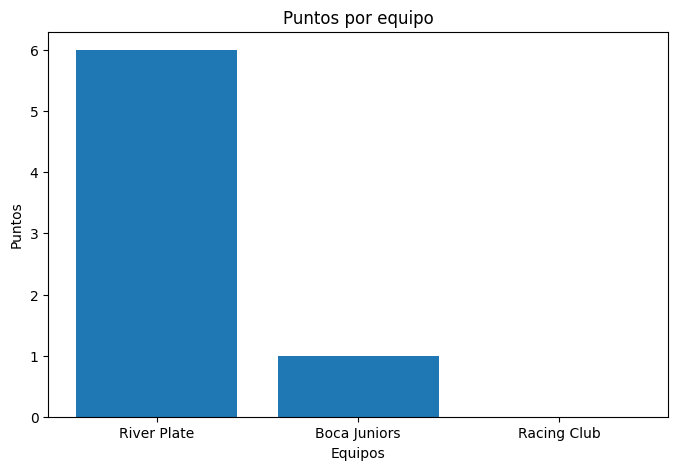

In [22]:
plt.figure(figsize=(8,5))
plt.bar(posiciones["Equipo"], posiciones["Puntos"])

plt.title("Puntos por equipo")
plt.xlabel("Equipos")
plt.ylabel("Puntos")
plt.show()

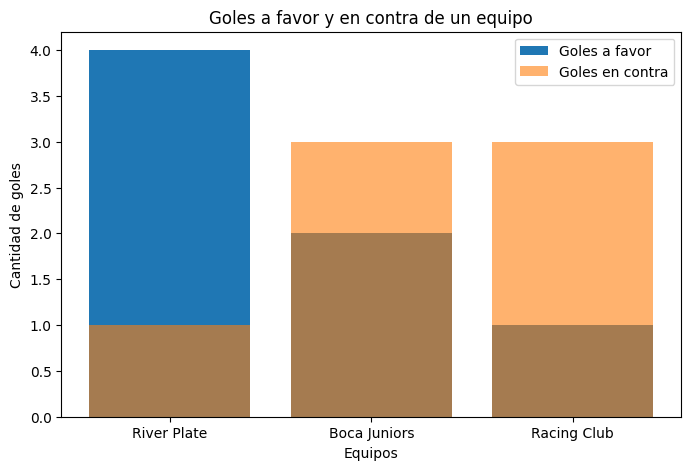

In [23]:
plt.figure(figsize=(8,5))

plt.bar(
    posiciones["Equipo"],
    posiciones["GF"],
    label = "Goles a favor"
)

plt.bar(
    posiciones["Equipo"],
    posiciones["GC"],
    label="Goles en contra",
    alpha=0.6
)

plt.title("Goles a favor y en contra de un equipo")
plt.xlabel("Equipos")
plt.ylabel("Cantidad de goles")
plt.legend()

plt.show()

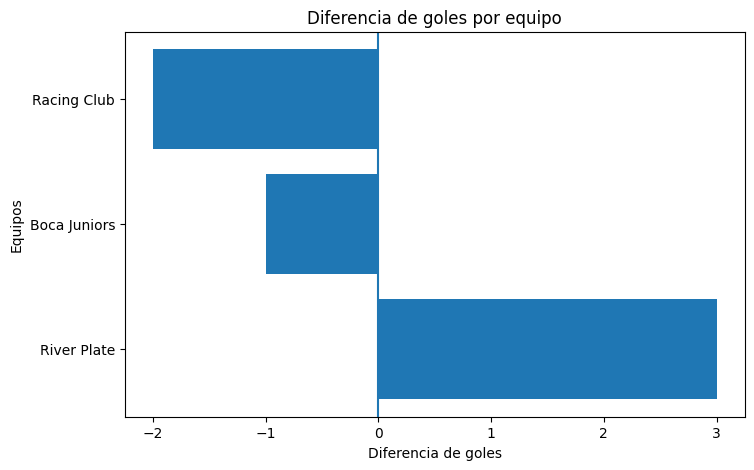

In [24]:
plt.figure(figsize=(8,5))

plt.barh(
    posiciones["Equipo"],
    posiciones["DG"]
)

plt.title("Diferencia de goles por equipo")
plt.xlabel("Diferencia de goles")
plt.ylabel("Equipos")
plt.axvline(x=0)
plt.show()